# 1. Contexte métier et problématique

## 1.1 Contexte

TouNum est une entreprise spécialisée dans la numérisation de documents, notamment à partir de supports papier. Dans le cadre de l'augmentation du volume de documents numérisés, l'entreprise souhaite développer de nouveaux services reposant sur les techniques de Machine Learning.

L'un des objectifs du projet consiste à mettre en place une chaîne automatisée permettant d'analyser des images et, à terme, de générer automatiquement une légende descriptive de leur contenu.

Avant de réaliser cette étape de génération de légendes (*image captioning*), une étape de filtrage est nécessaire. En effet, l'ensemble des images numérisées par TouNum ne correspond pas nécessairement à des photographies. Le dataset peut également contenir des schémas, des graphiques, des textes scannés, des dessins ou encore des peintures.

L'objectif de ce premier livrable est donc de développer un modèle de classification capable de distinguer automatiquement :

* les **photographies** ;
* les **autres types d'images**.

Cette classification permettra de sélectionner automatiquement les photographies qui pourront ensuite être transmises aux étapes suivantes du workflow.

## 1.2 Problématique

La problématique étudiée dans ce livrable est donc la suivante :

**Comment développer un modèle de réseau de neurones capable de distinguer automatiquement une photographie d'une autre catégorie d'image dans un ensemble de documents numérisés ?**

La difficulté du problème dépend notamment de la nature des images à distinguer. Les textes scannés ou les schémas présentent généralement des caractéristiques visuelles très différentes des photographies. À l'inverse, certaines peintures possèdent un rendu très réaliste et peuvent donc être visuellement proches d'une photographie.

L'objectif sera ainsi de construire progressivement un modèle, d'évaluer ses performances et d'analyser ses limites afin de déterminer s'il est suffisamment pertinent pour être intégré au workflow de TouNum.


# 2. Objectif de la classification

Le problème est formulé comme une **classification binaire supervisée**.

Deux classes sont retenues :

| Classe | Signification | Exemples                                          |
| ------ | ------------- | ------------------------------------------------- |
| `0`    | Autre         | Schéma, graphique, texte scanné, dessin, peinture |
| `1`    | Photo         | Photographie                                      |

Les datasets fournis par TouNum sont initialement répartis dans différents répertoires selon leur nature. L'absence d'étiquette explicite dans les fichiers ne constitue donc pas un problème : la classe pourra être automatiquement déterminée à partir du répertoire dans lequel se trouve chaque image.

L'objectif final est d'obtenir un modèle capable de prendre une image en entrée et de produire une prédiction binaire :

**Image → Réseau de neurones → Photo / Autre**

Cette première classification constitue une étape de filtrage. Les images identifiées comme des photographies pourront ensuite être transmises aux étapes de traitement d'image et de génération automatique de légendes.


## 3. Importation des librairies

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import imageio.v3 as iio

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow :", tf.__version__)

TensorFlow : 2.21.0


## 4. Exploration et préparation des données

Avant l'entraînement du réseau de neurones, une phase d'exploration des données est nécessaire.

Cette étape permet notamment de :

* vérifier la structure du dataset ;
* connaître le nombre d'images disponibles par catégorie ;
* identifier un éventuel déséquilibre entre les classes ;
* vérifier les formats des images ;
* observer visuellement un échantillon des données.

Cette analyse est importante car la qualité et la répartition des données peuvent directement influencer les performances du modèle.


In [2]:
# Dossier racine du projet
DATASET_DIR = "."

# Correspondance entre les dossiers et les classes
folders = {
    "Dataset Livrable 1 - Photo": 1,
    "Dataset Livrable 1 - Painting": 0,
    "Dataset Livrable 1 - Schematics": 0,
    "Dataset Livrable 1 - Sketch": 0,
    "Dataset Livrable 1 - Text": 0
}

# Extensions d'images acceptées
extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

data = []

for folder, label in folders.items():

    folder_path = os.path.join(DATASET_DIR, folder)

    # Parcours récursif de tous les sous-dossiers
    for root, dirs, files in os.walk(folder_path):

        for filename in files:

            if filename.lower().endswith(extensions):

                filepath = os.path.join(root, filename)

                data.append({
                    "filepath": filepath,
                    "category": folder,
                    "label": label
                })

# Création du DataFrame
df = pd.DataFrame(data)

print("Nombre total d'images :", len(df))
print("\nRépartition par catégorie :")
print(df["category"].value_counts())
print("\nRépartition des classes :")
print(df["label"].value_counts())




Nombre total d'images : 41399

Répartition par catégorie :
category
Dataset Livrable 1 - Painting      10000
Dataset Livrable 1 - Text          10000
Dataset Livrable 1 - Schematics    10000
Dataset Livrable 1 - Photo          9993
Dataset Livrable 1 - Sketch         1406
Name: count, dtype: int64

Répartition des classes :
label
0    31406
1     9993
Name: count, dtype: int64


label
0    75.861736
1    24.138264
Name: proportion, dtype: float64


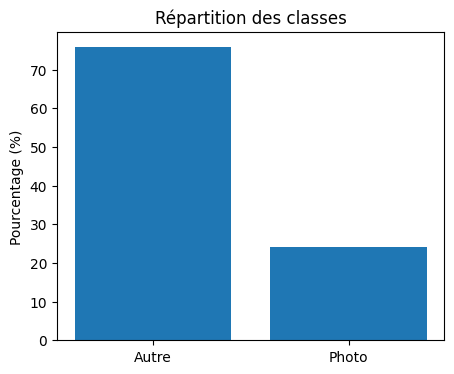

In [3]:
# Déséquilibre des classes
class_distribution = df["label"].value_counts(normalize=True) * 100

print(class_distribution)

plt.figure(figsize=(5, 4))

plt.bar(
    ["Autre", "Photo"],
    [
        class_distribution.get(0, 0),
        class_distribution.get(1, 0)
    ]
)

plt.ylabel("Pourcentage (%)")
plt.title("Répartition des classes")

plt.show()

.\Dataset Livrable 1 - Painting\Painting\painting_03286.jpg (998, 818, 3)
.\Dataset Livrable 1 - Painting\Painting\painting_07032.jpg (2668, 2024, 3)
.\Dataset Livrable 1 - Schematics\Schematics\schematics_06891.jpg (530, 384, 3)
.\Dataset Livrable 1 - Schematics\Schematics\schematics_08192.jpg (848, 1386, 3)
.\Dataset Livrable 1 - Text\Text\text_05127.jpg (842, 595, 3)
.\Dataset Livrable 1 - Schematics\Schematics\schematics_04464.jpg (559, 666, 3)
.\Dataset Livrable 1 - Schematics\Schematics\schematics_01373.jpg (820, 860, 3)
.\Dataset Livrable 1 - Text\Text\text_07264.jpg (526, 385, 3)
.\Dataset Livrable 1 - Sketch\Sketch\2899.png (1111, 1111)
.\Dataset Livrable 1 - Painting\Painting\painting_02627.jpg (803, 1077, 3)


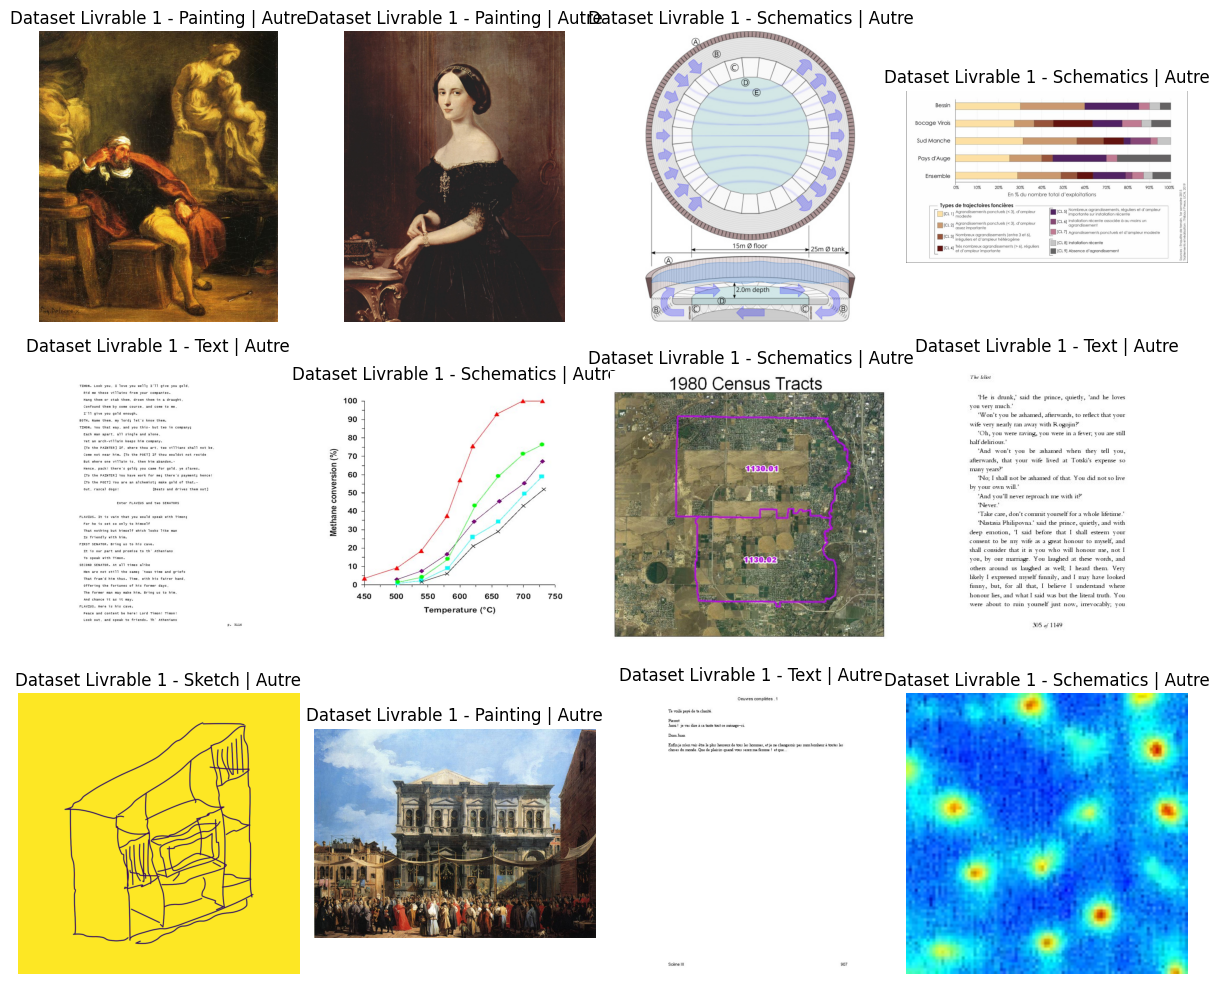

In [4]:
# Vérification de la validité des images (height, width), 3 canaux pour les images RGB (Red, Green, Blue)

def check_image(filepath):
    try:
        image = iio.imread(filepath)
        return image.shape
    except Exception:
        return None
for filepath in df["filepath"].sample(
    min(10, len(df)),
    random_state=42
):
    print(filepath, check_image(filepath))

# Visualisation de quelques images

sample_df = df.sample(
    min(12, len(df)),
    random_state=42
)

plt.figure(figsize=(12, 10))

for i, (_, row) in enumerate(sample_df.iterrows()):
    
    image = iio.imread(row["filepath"])
    
    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"{row['category']} | "
        f"{'Photo' if row['label'] == 1 else 'Autre'}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

## 5. Séparation du dataset

Afin d'évaluer la capacité de généralisation du modèle, le dataset est séparé en trois sous-ensembles :

* **jeu d'entraînement** : utilisé pour apprendre les paramètres du réseau ;
* **jeu de validation** : utilisé pendant le développement pour suivre les performances et détecter un éventuel sur-apprentissage ;
* **jeu de test** : conservé à part et utilisé uniquement pour l'évaluation finale du modèle.

Une répartition de 70 % / 15 % / 15 % est retenue.

La séparation est réalisée de manière stratifiée afin de conserver une proportion similaire de photographies et d'autres images dans les différents sous-ensembles.


In [5]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Train :", len(train_df))
print("Validation :", len(val_df))
print("Test :", len(test_df))


Train : 28979
Validation : 6210
Test : 6210


In [6]:
# Préparation des données pour TensorFlow

IMG_HEIGHT = 224  # car c'est la taile standard pour les réseaux de classification d'images
IMG_WIDTH = 224
BATCH_SIZE = 32

def load_image(filepath, label):
    
    image = tf.io.read_file(filepath)
    
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    
    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH]
    )
    
    image = tf.cast(image, tf.float32) / 255.0
    
    return image, label
def create_tf_dataset(dataframe, shuffle=False):
    
    paths = dataframe["filepath"].values
    labels = dataframe["label"].values
    
    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )
    
    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    
    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )
    
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    
    return dataset
train_ds = create_tf_dataset(
    train_df,
    shuffle=True
)

val_ds = create_tf_dataset(
    val_df
)

test_ds = create_tf_dataset(
    test_df
)

# Détection des images illisibles
def is_valid_image(filepath):
    try:
        raw = tf.io.read_file(filepath)
        image = tf.image.decode_image(
            raw,
            channels=3,
            expand_animations=False
        )
        tf.ensure_shape(image, [None, None, 3])
        return True
    except Exception:
        return False


valid_paths = {
    filepath
    for filepath in df["filepath"]
    if is_valid_image(filepath)
}

invalid_paths = set(df["filepath"]) - valid_paths

print("Images invalides supprimées :", len(invalid_paths))

# Filtrage des sous-ensembles
train_df = train_df[train_df["filepath"].isin(valid_paths)].copy()
val_df = val_df[val_df["filepath"].isin(valid_paths)].copy()
test_df = test_df[test_df["filepath"].isin(valid_paths)].copy()

# Recréation des datasets
train_ds = create_tf_dataset(train_df, shuffle=True)
val_ds = create_tf_dataset(val_df)
test_ds = create_tf_dataset(test_df)

# Vérification
for images, labels in train_ds.take(1):
    print("Dimensions des images :", images.shape)
    print("Dimensions des labels :", labels.shape)
    print(
        "Valeurs des pixels :",
        images.numpy().min(),
        "->",
        images.numpy().max()       # le premier 32 sera simplement le nombre d'images dans le batch, tandis que 224, 224, 3 décrit chaque image.
    )


Images invalides supprimées : 1
Dimensions des images : (32, 224, 224, 3)
Dimensions des labels : (32,)
Valeurs des pixels : 0.0 -> 1.0


# 6. Construction du modèle CNN

Un réseau de neurones convolutif (CNN) est utilisé car il est particulièrement adapté à l'analyse d'images.

Les couches de convolution permettent d'extraire progressivement des caractéristiques visuelles :
- contours ;
- textures ;
- formes ;
- motifs plus complexes.

Les couches de MaxPooling réduisent progressivement la résolution spatiale des représentations tout en conservant les informations les plus importantes.

Une couche Flatten transforme ensuite la représentation multidimensionnelle en vecteur afin de pouvoir utiliser des couches denses pour la classification.

La dernière couche contient un seul neurone associé à une fonction d'activation sigmoïde. Elle produit une probabilité comprise entre 0 et 1 correspondant à la probabilité que l'image appartienne à la classe « Photo ».

In [7]:
from tensorflow import keras
from tensorflow.keras import layers

model_baseline = keras.Sequential([

    layers.Input(
        shape=(IMG_HEIGHT, IMG_WIDTH, 3)
    ),

    layers.Conv2D(
        32,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Flatten(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dense(
        1,
        activation="sigmoid"
    )
])

# Afficher l'architecture
model_baseline.compile(
  
)

# Fonction de perte et optimiseur

model_baseline.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy"
    ]
)

## 7.1 Fonction de perte

Le problème étant une classification binaire, la fonction de perte `binary_crossentropy` est utilisée.

Elle mesure l'écart entre la probabilité prédite par le réseau et la classe réelle.

## 7.2 Optimisation

L'optimiseur Adam est utilisé pour ajuster automatiquement les poids du réseau au cours de l'entraînement.

Un taux d'apprentissage initial de 0,001 est retenu.

## 7.3 Fonction d'activation finale

La dernière couche utilise une fonction sigmoïde.

La sortie du réseau est donc comprise entre 0 et 1 :

- valeur proche de 0 → Autre ;
- valeur proche de 1 → Photo.

Un seuil de 0,5 sera utilisé pour transformer cette probabilité en prédiction binaire.

{np.int64(0): np.float64(0.6591002138015739), np.int64(1): np.float64(2.071336669049321)}
Epoch 1/5
906/906 ━━━━━━━━━━━━━━━━━━━━ 1015s 945ms/step - accuracy: 0.7728 - loss: 0.4019 - val_accuracy: 0.8575 - val_loss: 0.3009
Epoch 2/5
906/906 ━━━━━━━━━━━━━━━━━━━━ 977s 904ms/step - accuracy: 0.8304 - loss: 0.3206 - val_accuracy: 0.8441 - val_loss: 0.3172
Epoch 3/5
906/906 ━━━━━━━━━━━━━━━━━━━━ 1001s 945ms/step - accuracy: 0.8807 - loss: 0.2511 - val_accuracy: 0.8390 - val_loss: 0.3911
Epoch 4/5
906/906 ━━━━━━━━━━━━━━━━━━━━ 967s 908ms/step - accuracy: 0.9076 - loss: 0.2043 - val_accuracy: 0.8928 - val_loss: 0.2482
Epoch 5/5
906/906 ━━━━━━━━━━━━━━━━━━━━ 993s 907ms/step - accuracy: 0.9402 - loss: 0.1413 - val_accuracy: 0.8797 - val_loss: 0.2858


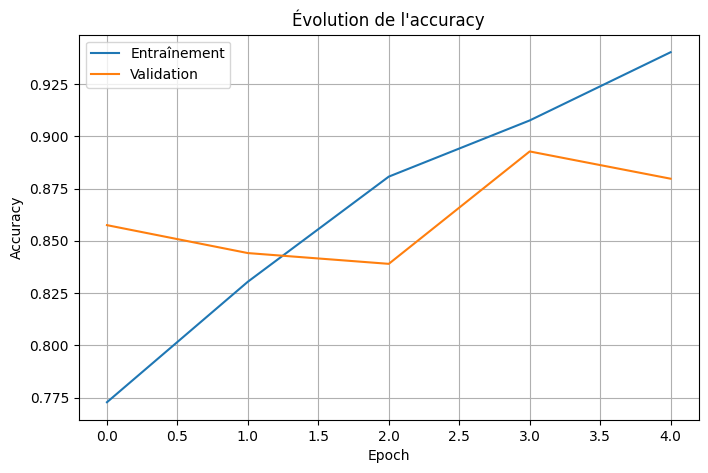

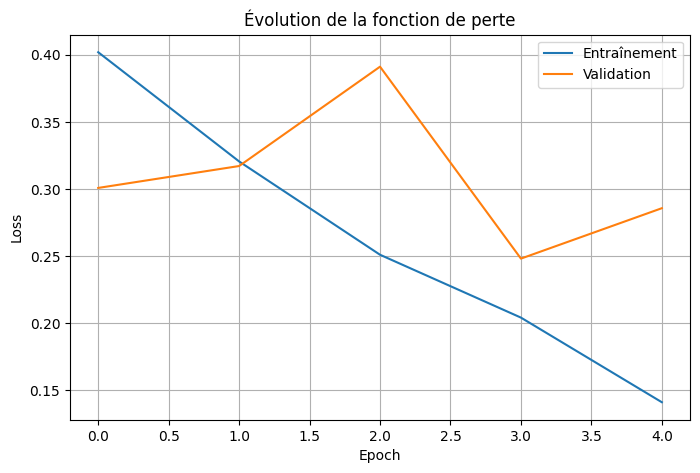

In [8]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(train_df["label"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"]
)

class_weights = dict(
    zip(classes, weights)
)

print(class_weights)

history_baseline = model_baseline.fit(

    train_ds,

    validation_data=val_ds,

    epochs=5,

    class_weight=class_weights
)

# Accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    history_baseline.history["accuracy"],
    label="Entraînement"
)

plt.plot(
    history_baseline.history["val_accuracy"],
    label="Validation"
)

plt.title("Évolution de l'accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

# Loss

plt.figure(figsize=(8, 5))

plt.plot(
    history_baseline.history["loss"],
    label="Entraînement"
)

plt.plot(
    history_baseline.history["val_loss"],
    label="Validation"
)

plt.title("Évolution de la fonction de perte")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()